# FBI IC3 2023 — Reported Cybercrime Patterns in the United States

This notebook examines geographic differences in FBI IC3 complaints and reported financial losses in 2023, differences across crime types, victim age groups and critical infrastructure sectors, and their associations with state-level economic indicators and UMD documented incidents.

**Original data sources:** [FBI IC3 Annual Reports](https://www.ic3.gov/AnnualReport) · [2023 FBI IC3 State Reports](https://www.ic3.gov/AnnualReport/Reports/2023State/)



In [23]:
# Libraries, paths and data loading
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from scipy.stats import pearsonr, spearmanr, shapiro, norm
from IPython.display import display

In [24]:
PROJECT_ROOT = Path("../..").resolve()  # Notebook: usa/notebooks/ic3/
IC3_ANNUAL_DIR = PROJECT_ROOT / "data/processed/ic3/annual"
IC3_STATE_DIR = PROJECT_ROOT / "data/processed/ic3/state_reports"
ECONOMIC_DIR = PROJECT_ROOT / "data/processed/economic/combined"
STATIC_DIR = PROJECT_ROOT / "figures/ic3/static"
INTERACTIVE_DIR = PROJECT_ROOT / "figures/ic3/interactive"
IC3_ANALYSIS_DIR = PROJECT_ROOT / "data/processed/ic3/analysis"

for directory in (STATIC_DIR, INTERACTIVE_DIR, IC3_ANALYSIS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

In [25]:
# 2023 Annual Report
ic3_state = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_state_2023.csv")
ic3_crime = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_crime_2023.csv")
ic3_sector = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_sector_2023.csv")

# 2023 State Reports
ic3_state_crime = pd.read_csv(IC3_STATE_DIR / "fbi_ic3_state_crime_2023.csv")
ic3_state_age = pd.read_csv(IC3_STATE_DIR / "fbi_ic3_state_age_2023.csv")

In [26]:
# Reference datasets: 2014–2025 economic panel and UMD panel.
economic_factors = pd.read_csv(
    ECONOMIC_DIR / "usa_state_economic_factors_2014_2025.csv"
)
umd_incidents_economic = pd.read_csv(
    ECONOMIC_DIR / "usa_state_incidents_economic_2014_2025.csv"
)

In [27]:
ic3_datasets = {
    "State overview": ic3_state,
    "National crime": ic3_crime,
    "Critical infrastructure": ic3_sector,
    "State crime": ic3_state_crime,
    "State age": ic3_state_age,
}
expected_columns = {
    "State overview": {"state", "year", "complaints", "loss_usd", "complaints_per_100k", "loss_per_100k_usd"},
    "National crime": {"year", "crime_type", "category_kind", "complaints", "loss_usd"},
    "Critical infrastructure": {"sector", "year", "ransomware_complaints"},
    "State crime": {"state", "year", "category", "category_kind", "victim_count", "victim_loss_usd"},
    "State age": {"state", "year", "age_group", "victim_count", "victim_loss_usd"},
}
for name, frame in ic3_datasets.items():
    missing = expected_columns[name] - set(frame.columns)
    if missing:
        raise ValueError(f"{name}: missing columns {sorted(missing)}")
    if not frame["year"].eq(2023).all():
        raise ValueError(f"{name}: unexpected years")
print(f"Loaded {len(ic3_datasets)} FBI IC3 datasets for 2023.")
print(f"Project root: {PROJECT_ROOT}")

Loaded 5 FBI IC3 datasets for 2023.
Project root: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa


## 1. Data Sources and Coverage

Five FBI IC3 datasets describe 2023 complaints and reported losses by state, crime type and age group, together with ransomware complaints by critical-infrastructure sector. Annual Report and State Reports statistics are treated as separate sources.


### 1.1 Dataset Inventory

The five datasets contain 1,878 records. The Annual Report contributes three datasets; the State Reports contribute two.


In [28]:
dataset_sources = {
    "State overview": "Annual Report",
    "National crime": "Annual Report",
    "Critical infrastructure": "Annual Report",
    "State crime": "State Reports",
    "State age": "State Reports",
}
dataset_inventory = pd.DataFrame([
    {"Dataset": name, "Source": dataset_sources[name], "Rows": len(df),
     "Columns": df.shape[1], "Missing values": int(df.isna().sum().sum())}
    for name, df in ic3_datasets.items()
])
display(dataset_inventory)

,Dataset,Source,Rows,Columns,Missing values
0,State overview,Annual Report,51,8,0
1,National crime,Annual Report,28,8,0
2,Critical infrastructure,Annual Report,14,7,14
3,State crime,State Reports,1479,9,0
4,State age,State Reports,306,6,0


## 2. Data Quality and Descriptive Overview

The datasets were checked for missing measurements, duplicate records, negative values and state coverage. Missing sector-level data breach figures are distinguished from reported zeros.


### 2.1 Missing Values

Only the critical-infrastructure dataset has missing numerical entries: all 14 data breach counts are unavailable in the 2023 Annual Report. The reported ransomware counts remain complete.


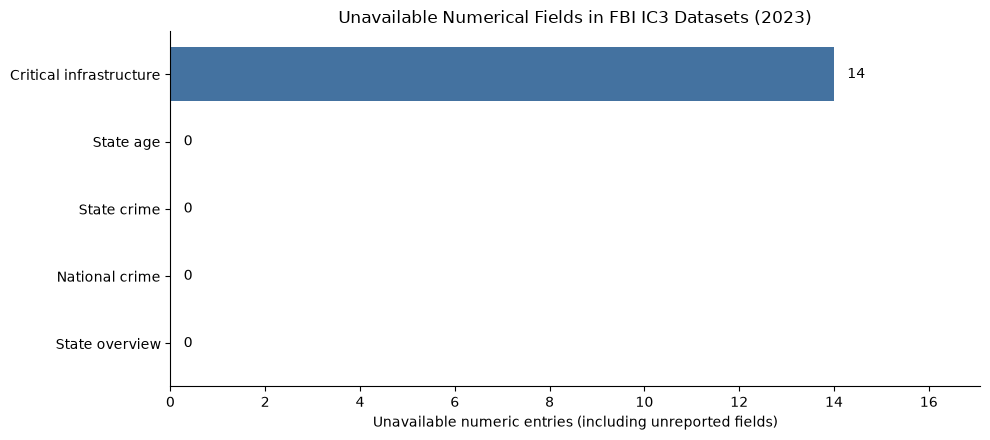

In [29]:
missing_numeric = pd.Series({
    name: int(df.select_dtypes(include="number").isna().sum().sum())
    for name, df in ic3_datasets.items()
}).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(missing_numeric.index, missing_numeric.values, color="#4472A0")
for bar, value in zip(bars, missing_numeric.values):
    ax.text(value + max(missing_numeric.max() * .02, .05),
            bar.get_y() + bar.get_height()/2, f"{value}", va="center")
ax.set_xlim(0, max(missing_numeric.max() * 1.22, 1))
ax.set_xlabel("Unavailable numeric entries (including unreported fields)")
ax.set_title("Unavailable Numerical Fields in FBI IC3 Datasets (2023)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(STATIC_DIR / "02_01_missing_values_2023.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.2 Data Consistency

No duplicate rows, duplicate identifiers or negative measurements were detected. All three state-level datasets cover 50 states and Washington, D.C.; each state has six age groups. The sector ransomware counts sum to 1,193.


In [30]:
dataset_keys = {
    "State overview": ["state", "year"],
    "National crime": ["year", "crime_type"],
    "Critical infrastructure": ["year", "sector"],
    "State crime": ["state", "year", "category"],
    "State age": ["state", "year", "age_group"],
}
consistency_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Duplicate rows": int(df.duplicated().sum()),
        "Duplicate keys": int(df.duplicated(subset=dataset_keys[name]).sum()),
        "Negative values": int((df.select_dtypes(include="number").drop(columns=["year"], errors="ignore") < 0).sum().sum()),
        "States": df["state"].nunique() if "state" in df else np.nan,
    }
    for name, df in ic3_datasets.items()
])
display(consistency_summary)

,Dataset,Duplicate rows,Duplicate keys,Negative values,States
0,State overview,0,0,0,51.0
1,National crime,0,0,0,NaN
2,Critical infrastructure,0,0,0,NaN
3,State crime,0,0,0,51.0
4,State age,0,0,0,51.0


In [31]:
# Geographic coverage and sector-metric availability
expected_states = set(ic3_state["state"])
assert len(expected_states) == 51, "Annual Report must contain 50 states and D.C."
assert set(ic3_state_crime["state"]) == expected_states
assert set(ic3_state_age["state"]) == expected_states
assert ic3_state_age.groupby("state")["age_group"].nunique().eq(6).all()
assert ic3_sector["ransomware_complaints"].sum() == 1193
assert ic3_sector["data_breach_complaints"].isna().all()
print("Geographic and age coverage verified; ransomware sector sum = 1,193.")
print("Data breach counts by sector are not reported for 2023.")

Geographic and age coverage verified; ransomware sector sum = 1,193.
Data breach counts by sector are not reported for 2023.


## 3. Research Questions and Visual Analysis

Reported complaints, financial losses and their geographic distribution are examined alongside crime composition, age groups and sectors. Economic associations and comparisons with UMD are exploratory and do not establish causation.


### 3.1 Which states stand out in reported complaints and financial losses?

California, Texas and Florida lead in absolute complaint counts and reported losses. Population-adjusted rankings differ substantially: Washington, D.C., has the highest complaint rate, while Washington, D.C., Nevada and California lead in loss rates.


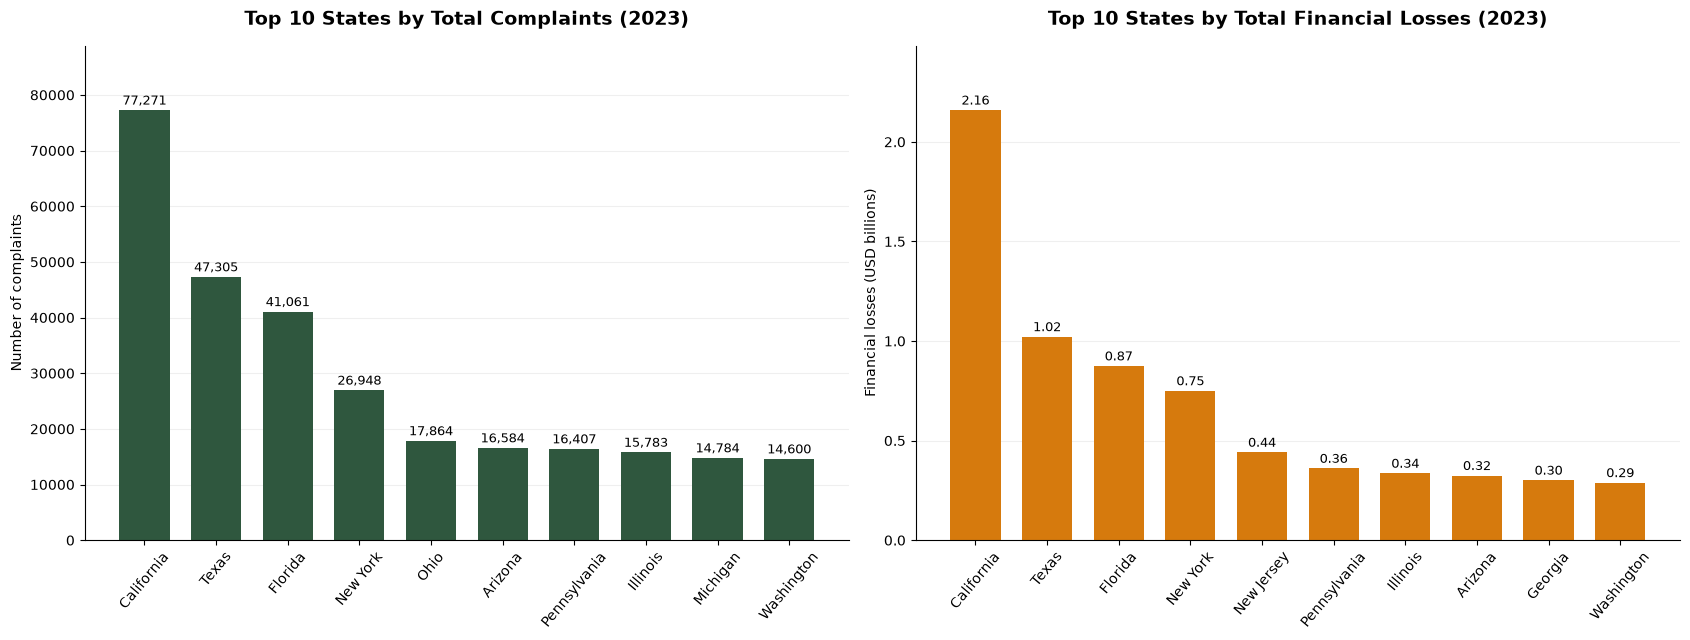

In [32]:
# Top 10 states by absolute complaints and financial losses
top_complaints_abs = ic3_state.nlargest(10, "complaints")
top_losses_abs = ic3_state.nlargest(10, "loss_usd").copy()
top_losses_abs["loss_billion"] = top_losses_abs["loss_usd"] / 1_000_000_000

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Total complaints
bars = axes[0].bar(
    top_complaints_abs["state"],
    top_complaints_abs["complaints"],
    color="#2F573E",
    width=0.7
)

axes[0].set_title(
    "Top 10 States by Total Complaints (2023)",
    fontsize=14, fontweight="bold", pad=15
)
axes[0].set_ylabel("Number of complaints")

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", fontsize=9
    )

# Total financial losses
bars = axes[1].bar(
    top_losses_abs["state"],
    top_losses_abs["loss_billion"],
    color="#D67A0D",
    width=0.7
)

axes[1].set_title(
    "Top 10 States by Total Financial Losses (2023)",
    fontsize=14, fontweight="bold", pad=15
)
axes[1].set_ylabel("Financial losses (USD billions)")

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:,.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", fontsize=9
    )

for ax in axes:
    ax.tick_params(axis="x", rotation=50)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

plt.tight_layout()
plt.savefig(
    STATIC_DIR / "03_02_top_states_absolute_2023.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

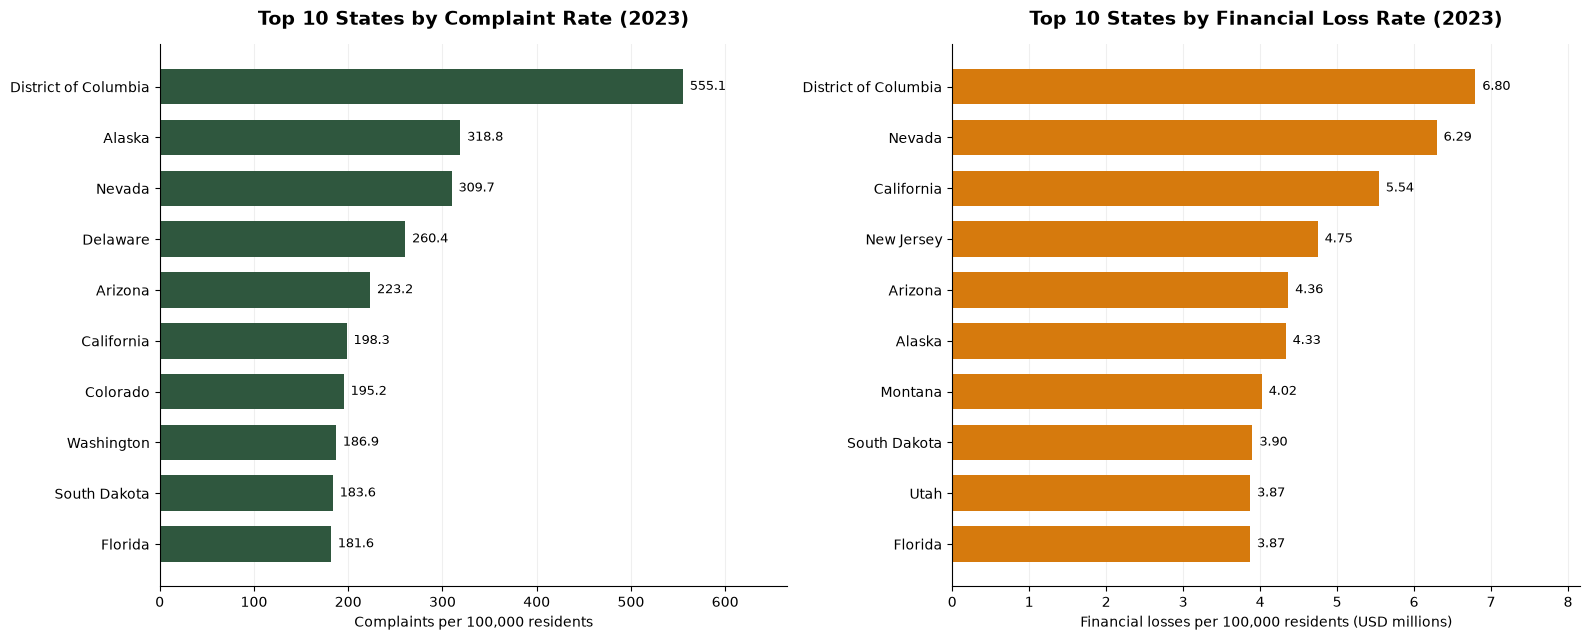

In [33]:
# Top 10 states by normalized complaint and financial loss rates
top_complaints = ic3_state.nlargest(10, "complaints_per_100k").sort_values("complaints_per_100k")
top_losses = ic3_state.nlargest(10, "loss_per_100k_usd").copy()
top_losses["loss_million"] = top_losses["loss_per_100k_usd"] / 1_000_000
top_losses = top_losses.sort_values("loss_million")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plots = [
    (top_complaints, "complaints_per_100k", "Top 10 States by Complaint Rate (2023)",
     "Complaints per 100,000 residents", "#2F573E", ".1f"),
    (top_losses, "loss_million", "Top 10 States by Financial Loss Rate (2023)",
     "Financial losses per 100,000 residents (USD millions)", "#D67A0D", ".2f"),
]
for ax, (data, column, title, xlabel, color, fmt) in zip(axes, plots):
    bars = ax.barh(data["state"], data[column], color=color, height=0.7)
    for bar in bars:
        val = bar.get_width()
        ax.annotate(format(val, fmt),
                    (val, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=14)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, data[column].max() * 1.2)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(STATIC_DIR / "03_01_top_states_normalized_2023.png",
            dpi=300, bbox_inches="tight")
plt.show()


### 3.2 Do states differ in the composition of reported cybercrime?

The distribution of crime types varies among the 15 states with the most IC3 complaints. The heatmap compares each category's share of primary crime-category victim counts, excluding overlapping descriptors from the denominator.


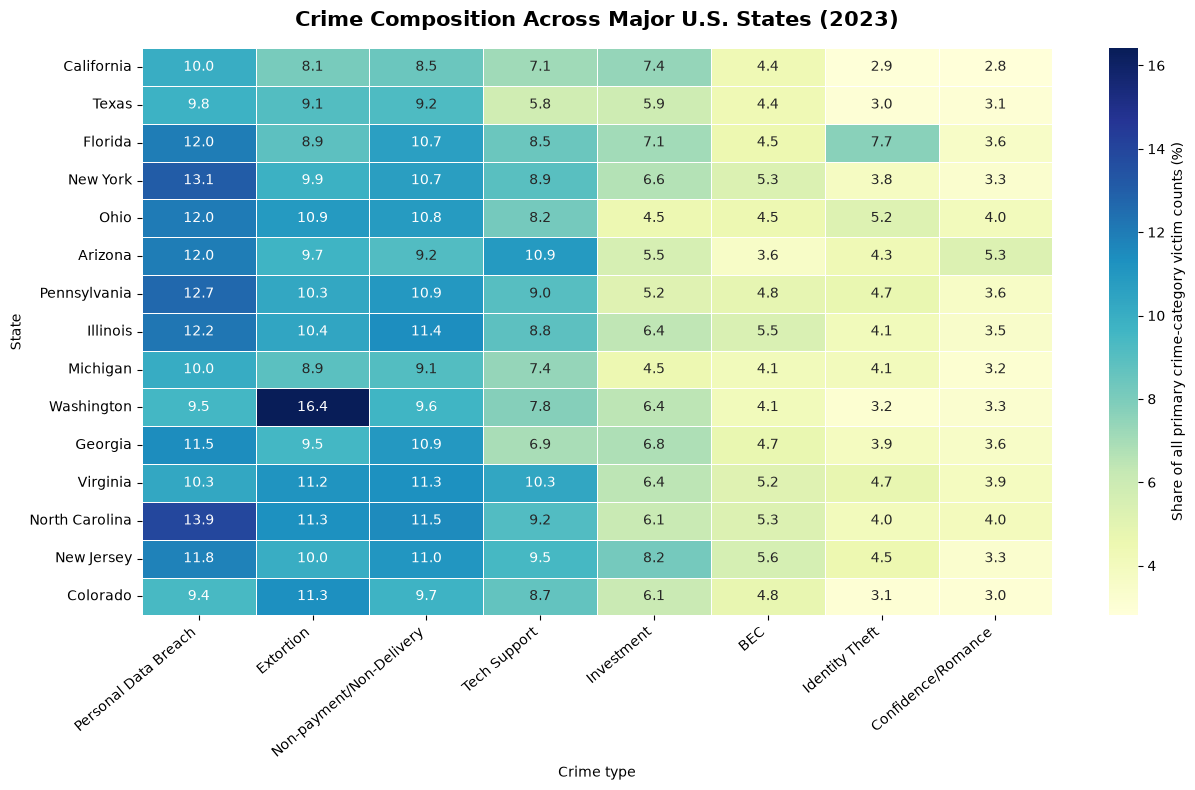

In [34]:
# Crime composition across the 15 states with most complaints

# Include all primary crime categories in the denominator
crime_data = ic3_state_crime[
    ic3_state_crime["category_kind"] == "crime_type"
].copy()

top_states = (
    ic3_state.nlargest(15, "complaints")["state"].tolist()
)

# Select the eight most common substantive crime categories
top_categories = (
    crime_data[
        ~crime_data["category"].isin(["No Lead Value", "Other"])
    ]
    .groupby("category")["victim_count"]
    .sum()
    .nlargest(8)
    .index.tolist()
)

# State-by-crime matrix for all primary categories
crime_matrix = crime_data.pivot_table(
    index="state",
    columns="category",
    values="victim_count",
    aggfunc="sum",
    fill_value=0
)

# Calculate shares using all primary category counts
crime_shares = crime_matrix.div(
    crime_matrix.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

# Display only the selected categories and states
heatmap_shares = crime_shares.loc[top_states, top_categories]

# Export the data behind the visualization
heatmap_shares.to_csv(
    IC3_ANALYSIS_DIR / "03_02_state_crime_composition_shares_2023.csv"
)

# Visualization
fig, ax = plt.subplots(figsize=(13, 8))

sns.heatmap(
    heatmap_shares,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Share of all primary crime-category victim counts (%)"},
    ax=ax
)

ax.set_title(
    "Crime Composition Across Major U.S. States (2023)",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Crime type")
ax.set_ylabel("State")

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_03_state_crime_composition_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.3 How do complaint and financial loss patterns differ across victim age groups?

The over-60 group accounts for the largest number of age-classified reported victims and the greatest reported financial losses. These totals exclude complaints without an indicated age and are not population-adjusted age-specific risks.


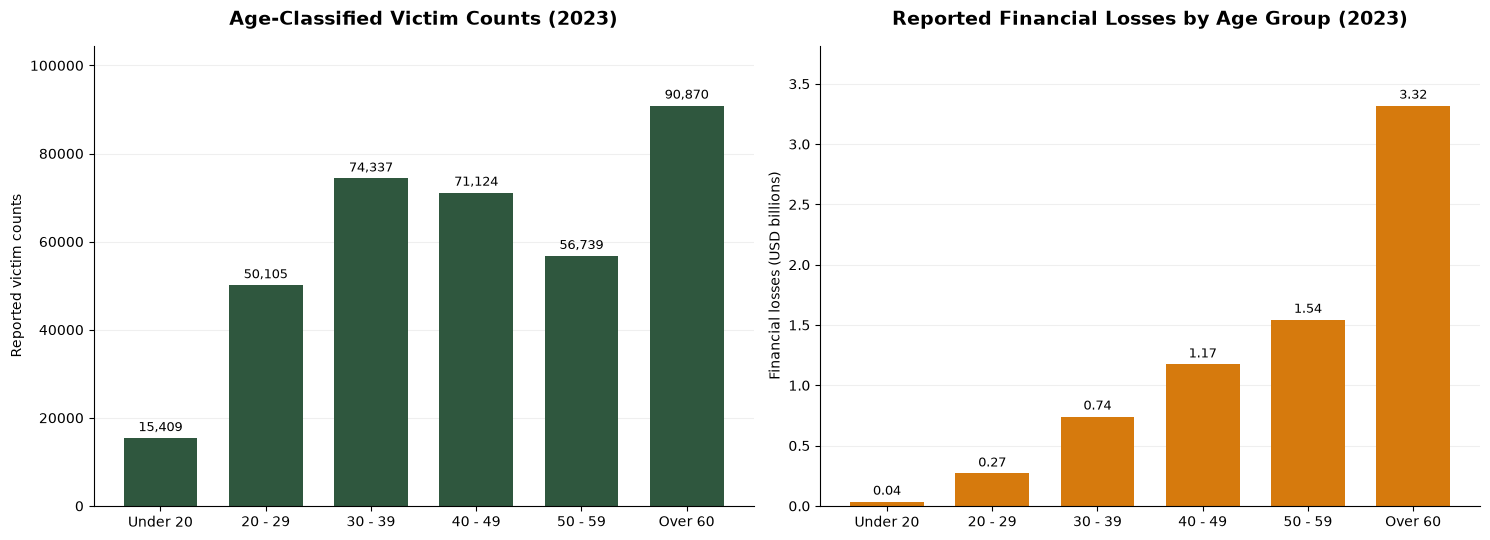

In [35]:
# Aggregate victims and financial losses across states
age_order = [
    "Under 20", "20 - 29", "30 - 39",
    "40 - 49", "50 - 59", "Over 60"
]

age_summary = (
    ic3_state_age.groupby("age_group", as_index=False)
    .agg(
        victims=("victim_count", "sum"),
        loss_usd=("victim_loss_usd", "sum")
    )
    .set_index("age_group")
    .reindex(age_order)
    .reset_index()
)

age_summary["loss_billion"] = age_summary["loss_usd"] / 1e9

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Number of victims
bars = axes[0].bar(
    age_summary["age_group"],
    age_summary["victims"],
    color="#2F573E",
    width=0.7
)

axes[0].set_title(
    "Age-Classified Victim Counts (2023)",
    fontsize=14, fontweight="bold", pad=15
)
axes[0].set_ylabel("Reported victim counts")

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", fontsize=9
    )

# Financial losses
bars = axes[1].bar(
    age_summary["age_group"],
    age_summary["loss_billion"],
    color="#D67A0D",
    width=0.7
)

axes[1].set_title(
    "Reported Financial Losses by Age Group (2023)",
    fontsize=14, fontweight="bold", pad=15
)
axes[1].set_ylabel("Financial losses (USD billions)")

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", fontsize=9
    )

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_05_victims_losses_by_age_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.4 Which critical infrastructure sectors stand out in ransomware complaints?

Healthcare and Public Health (249), Critical Manufacturing (218) and Government Facilities (156) have the most reported ransomware complaints. The 1,193 complaints span 14 sectors; sector-specific financial losses and data breach counts are not available in this table.


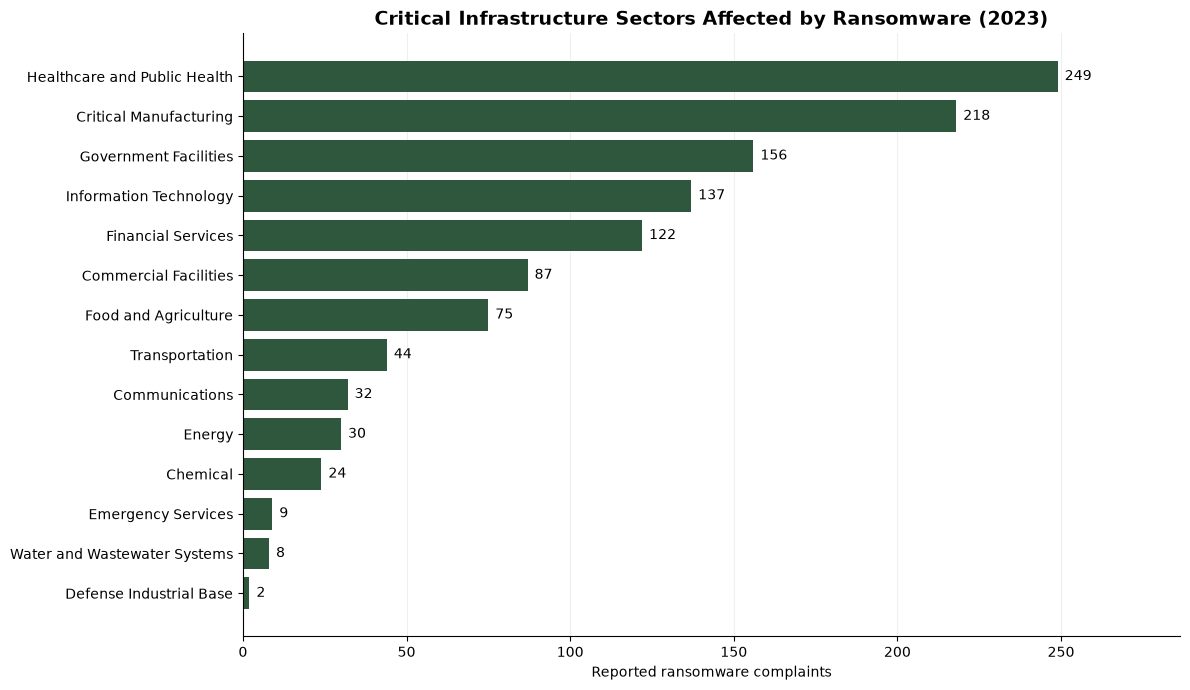

In [36]:
# Ransomware complaints in the 14 sectors reported for 2023
sector_data = ic3_sector.sort_values("ransomware_complaints").copy()
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(sector_data["sector"], sector_data["ransomware_complaints"], color="#2F573E")
for bar in bars:
    ax.annotate(f"{bar.get_width():,.0f}",
                (bar.get_width(), bar.get_y()+bar.get_height()/2),
                xytext=(5, 0), textcoords="offset points", va="center")
ax.set_xlabel("Reported ransomware complaints")
ax.set_title("Critical Infrastructure Sectors Affected by Ransomware (2023)",
             fontsize=14, fontweight="bold")
ax.set_xlim(0, sector_data["ransomware_complaints"].max()*1.15)
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(STATIC_DIR / "03_04_ransomware_by_sector_2023.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.5 Are reported cybercrime patterns associated with state-level economic factors?

Across 50 states, FBI IC3 complaint rates have positive Spearman correlations with average annual pay, GDP per capita, personal income per capita and unemployment. All four remain significant after Benjamini–Hochberg adjustment across seven tests (FDR 5%). These are unadjusted, cross-sectional associations.


In [37]:
# Align economic factors and FBI IC3 by state and year (exclude D.C.)
economic_2023 = economic_factors.loc[economic_factors["year"] == 2023].copy()
ic3_2023 = ic3_state.loc[ic3_state["year"] == 2023].copy()
assert economic_2023["state"].nunique() == len(economic_2023) == 50
ic3_economic = economic_2023.merge(
    ic3_2023, on=["state", "year"], how="left", validate="one_to_one", indicator=True
)
if not ic3_economic["_merge"].eq("both").all():
    raise ValueError("Missing FBI IC3 states in 2023 economic merge")
economic_features = {
    "gdp_per_capita": "GDP per capita",
    "personal_income_per_capita": "Personal income per capita",
    "real_gdp_growth_pct": "Real GDP growth",
    "unemployment_rate": "Unemployment rate",
    "labor_force_participation_rate": "Labor force participation",
    "establishments_per_10k": "Establishment density",
    "qcew_avg_annual_pay": "Average annual pay",
}
missing = [c for c in economic_features if c not in ic3_economic]
if missing:
    raise ValueError(f"Missing economic indicators: {missing}")
print(f"Matched economic/FBI state observations: {len(ic3_economic)}")
print("Missing complaint rates:", ic3_economic["complaints_per_100k"].isna().sum())

Matched economic/FBI state observations: 50
Missing complaint rates: 0


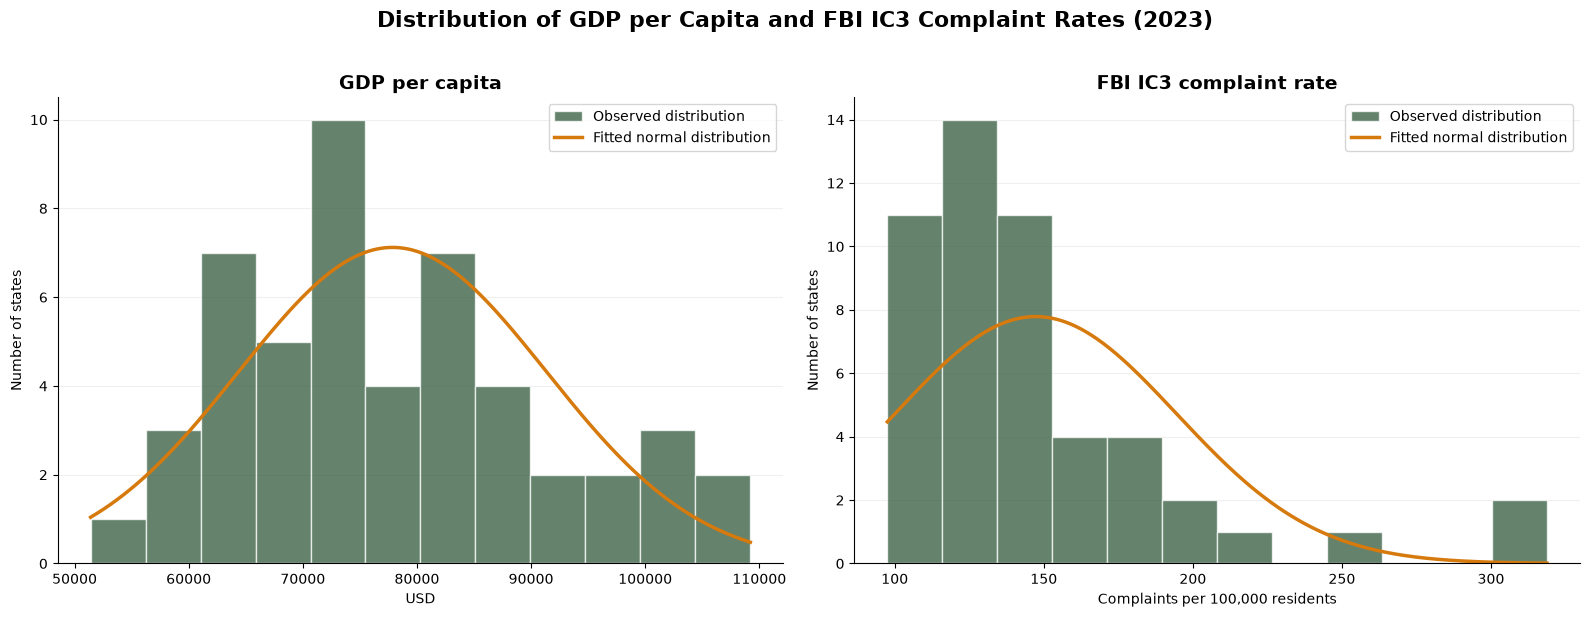

In [38]:
# Distribution assessment for FBI IC3 and GDP per capita (2023)
variables = [
    ("gdp_per_capita", "GDP per capita", "USD"),
    ("complaints_per_100k", "FBI IC3 complaint rate",
     "Complaints per 100,000 residents")
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (column, title, xlabel) in zip(axes, variables):
    values = ic3_economic[column].dropna().to_numpy()
    n_bins = 12

    counts, edges, _ = ax.hist(
        values,
        bins=n_bins,
        color="#31583B",
        alpha=0.75,
        edgecolor="white",
        label="Observed distribution"
    )

    # Fitted normal distribution scaled to histogram counts
    mu, sigma = norm.fit(values)
    x = np.linspace(values.min(), values.max(), 300)
    bin_width = edges[1] - edges[0]

    expected = norm.pdf(x, mu, sigma) * len(values) * bin_width

    ax.plot(
        x, expected,
        color="#D67A0D",
        linewidth=2.5,
        label="Fitted normal distribution"
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of states")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()

fig.suptitle(
    "Distribution of GDP per Capita and FBI IC3 Complaint Rates (2023)",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_08_fbi_economic_distributions_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Distribution assessment**

GDP per capita does not show a statistically significant departure from normality (Shapiro–Wilk p = 0.292); FBI IC3 complaint rates do (p < 0.001). Rank-based Spearman correlations are used consistently for the economic comparisons.


In [39]:
# Shapiro–Wilk normality tests
normality_results = []

for column, label in [
    ("gdp_per_capita", "GDP per capita"),
    ("complaints_per_100k", "FBI IC3 complaint rate")
]:
    values = ic3_economic[column].dropna()
    statistic, p_value = shapiro(values)

    normality_results.append({
        "Variable": label,
        "W statistic": round(statistic, 4),
        "p-value": round(p_value, 6),
        "Normality (α = 0.05)": (
            "Not rejected" if p_value >= 0.05 else "Rejected"
        )
    })

normality_summary = pd.DataFrame(normality_results)
display(normality_summary)

,Variable,W statistic,p-value,Normality (α = 0.05)
0,GDP per capita,0.9725,0.291943,Not rejected
1,FBI IC3 complaint rate,0.7829,0.000000,Rejected


In [40]:
# Spearman correlations and Benjamini–Hochberg adjustment
spearman_results = []
for column, label in economic_features.items():
    data = ic3_economic[[column, "complaints_per_100k"]].dropna()
    rho, p_value = spearmanr(data[column], data["complaints_per_100k"])
    spearman_results.append({
        "Economic factor": label, "N": len(data),
        "Spearman rho": rho, "p-value": p_value,
    })
spearman_summary = pd.DataFrame(spearman_results)
p = spearman_summary["p-value"].to_numpy(dtype=float)
order = np.argsort(p)
ranked = p[order]
adjusted = np.minimum.accumulate((ranked * len(p) / np.arange(1,len(p)+1))[::-1])[::-1]
adjusted_original = np.empty_like(adjusted)
adjusted_original[order] = np.clip(adjusted, 0, 1)
spearman_summary["BH-adjusted p-value"] = adjusted_original
spearman_summary["BH significant (FDR < 0.05)"] = adjusted_original < .05
spearman_summary = spearman_summary.sort_values("Spearman rho", ascending=False)
display(spearman_summary.round(4))

,Economic factor,N,Spearman rho,p-value,BH-adjusted p-value,BH significant (FDR < 0.05)
6,Average annual pay,50,0.4214,0.0023,0.0161,True
0,GDP per capita,50,0.3654,0.0091,0.0205,True
1,Personal income per capita,50,0.3547,0.0115,0.0205,True
3,Unemployment rate,50,0.3538,0.0117,0.0205,True
4,Labor force participation,50,0.0820,0.5714,0.8000,False
2,Real GDP growth,50,0.0049,0.9733,0.9733,False
5,Establishment density,50,-0.0293,0.8397,0.9733,False


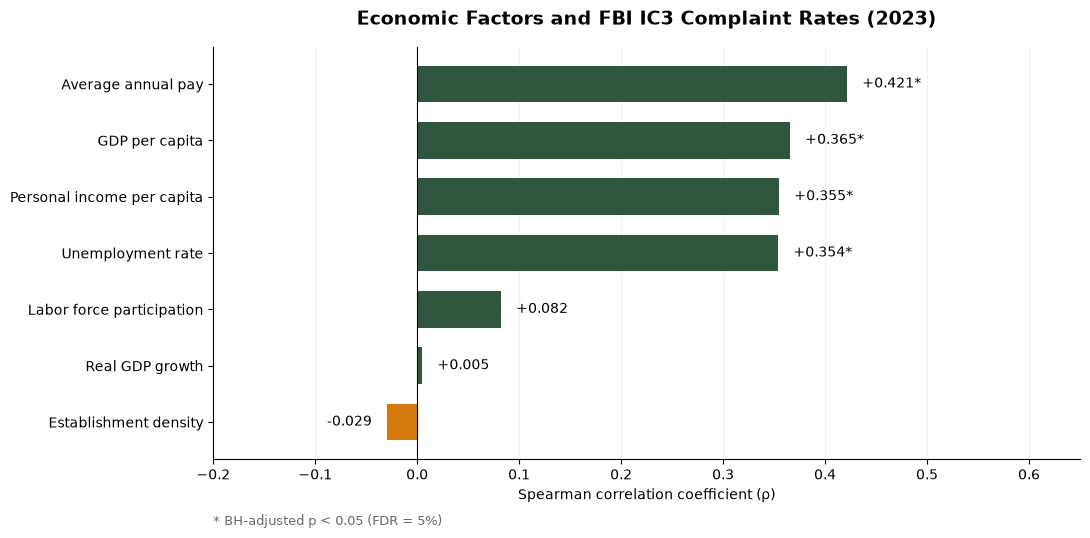

In [41]:
# Spearman correlations: FBI IC3 complaint rates and economic factors
plot_data = spearman_summary.sort_values("Spearman rho").copy()

colors = [
    "#2F573E" if rho >= 0 else "#D67A0D"
    for rho in plot_data["Spearman rho"]
]

fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.barh(
    plot_data["Economic factor"],
    plot_data["Spearman rho"],
    color=colors,
    height=0.65
)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    rho = row["Spearman rho"]
    marker = "*" if row["BH significant (FDR < 0.05)"] else ""
    offset = 0.015 if rho >= 0 else -0.015

    ax.text(
        rho + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{rho:+.3f}{marker}",
        va="center",
        ha="left" if rho >= 0 else "right",
        fontsize=10
    )

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.20, 0.65)
ax.set_xlabel("Spearman correlation coefficient (ρ)")
ax.set_title(
    "Economic Factors and FBI IC3 Complaint Rates (2023)",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.text(
    0, -0.16,
    "* BH-adjusted p < 0.05 (FDR = 5%)",
    transform=ax.transAxes,
    fontsize=9,
    color="dimgray"
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_09_fbi_economic_spearman_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.6 Do FBI IC3 and UMD reveal similar geographic patterns?

The two datasets capture different phenomena: FBI IC3 complaints and publicly documented UMD incidents. Their state rankings and associations with economic factors are compared for the same 50 states in 2023, without equating their event counts.


In [42]:
# Align UMD and FBI IC3 for the same states in 2023
umd_2023 = umd_incidents_economic.loc[
    umd_incidents_economic["year"] == 2023,
    ["state", "year", "incident_count", "incidents_per_100k"]
].copy()
comparison_2023 = ic3_economic.merge(
    umd_2023, on=["state", "year"], how="left", validate="one_to_one", indicator="umd_merge"
)
if not comparison_2023["umd_merge"].eq("both").all():
    raise ValueError("Not all 50 states are matched to UMD in 2023")
print("Matched FBI–UMD states:", len(comparison_2023))
print("UMD zero-incident states:", int(comparison_2023["incident_count"].eq(0).sum()))
print("Missing UMD rates:", int(comparison_2023["incidents_per_100k"].isna().sum()))

Matched FBI–UMD states: 50
UMD zero-incident states: 0
Missing UMD rates: 0


#### 3.6.1 Geographic Comparison

The states with the highest population-adjusted IC3 complaint rates are not the same as those with the highest UMD documented-incident rates. The two charts use separate scales because the measures and their magnitudes differ.


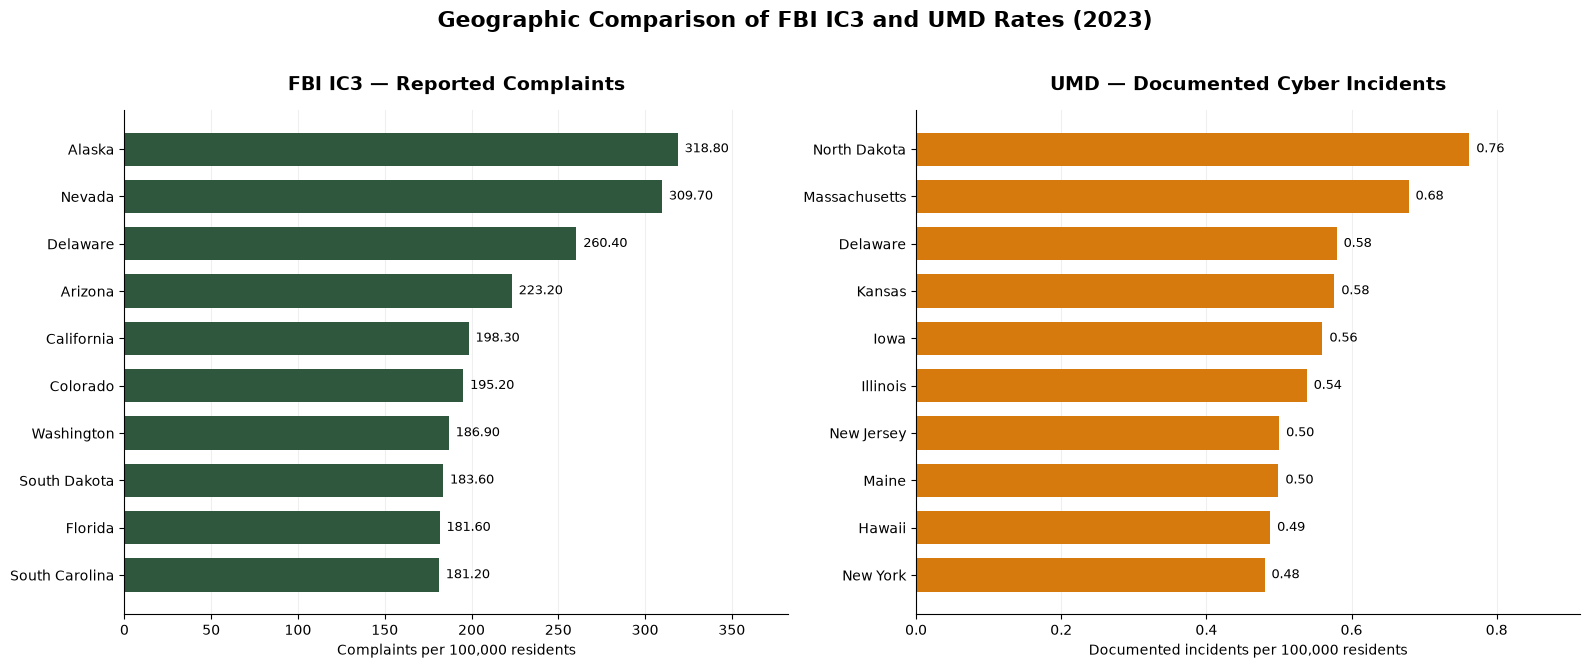

In [43]:
# Top 10 states by population-adjusted FBI IC3 and UMD rates
top_fbi = comparison_2023.nlargest(10, "complaints_per_100k").sort_values("complaints_per_100k")
top_umd = comparison_2023.nlargest(10, "incidents_per_100k").sort_values("incidents_per_100k")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plots = [
    (top_fbi, "complaints_per_100k", "FBI IC3 — Reported Complaints",
     "Complaints per 100,000 residents", "#2F573E"),
    (top_umd, "incidents_per_100k", "UMD — Documented Cyber Incidents",
     "Documented incidents per 100,000 residents", "#D67A0D"),
]

for ax, (data, column, title, xlabel, color) in zip(axes, plots):
    bars = ax.barh(data["state"], data[column], color=color, height=0.7)
    for bar in bars:
        value = bar.get_width()
        ax.annotate(
            f"{value:.2f}",
            (value, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0), textcoords="offset points", va="center", fontsize=9
        )
    ax.set_title(title, fontsize=14, fontweight="bold", pad=14)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, data[column].max() * 1.20)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Geographic Comparison of FBI IC3 and UMD Rates (2023)",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(STATIC_DIR / "03_10_fbi_umd_geographic_comparison_2023.png",
            dpi=300, bbox_inches="tight")
plt.show()


**Absolute counts**

California leads both sources in absolute counts, but FBI IC3 complaint totals are much larger than UMD documented-incident totals. The counts are not interchangeable and should not be interpreted as independent estimates of the same event population.


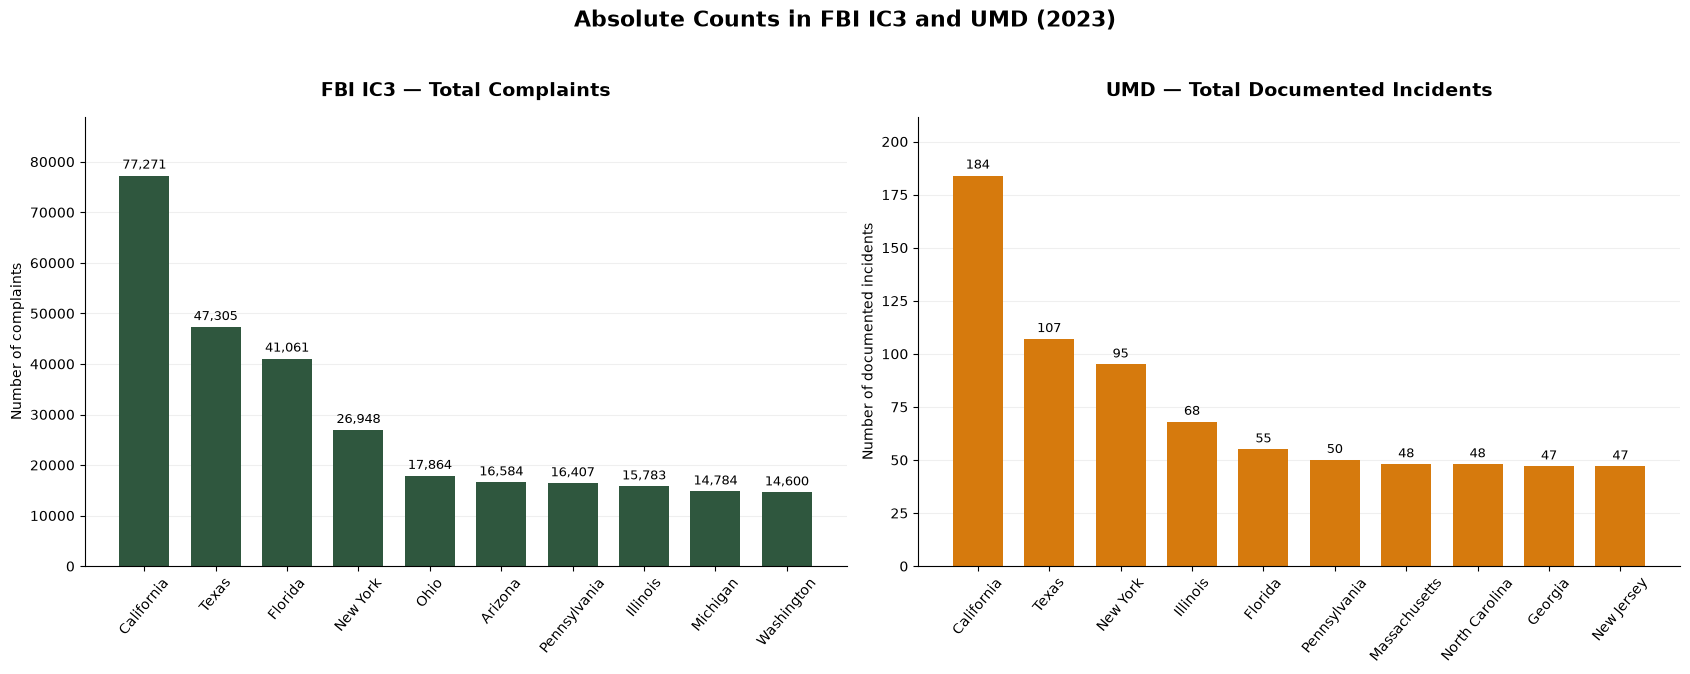

In [44]:
# Top 10 states by absolute counts in FBI IC3 and UMD

top_fbi_abs = comparison_2023.nlargest(
    10, "complaints"
)

top_umd_abs = comparison_2023.nlargest(
    10, "incident_count"
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

plots = [
    (
        top_fbi_abs,
        "complaints",
        "FBI IC3 — Total Complaints",
        "Number of complaints",
        "#2F573E"
    ),
    (
        top_umd_abs,
        "incident_count",
        "UMD — Total Documented Incidents",
        "Number of documented incidents",
        "#D67A0D"
    )
]

for ax, (data, column, title, ylabel, color) in zip(axes, plots):
    bars = ax.bar(
        data["state"],
        data[column],
        color=color,
        width=0.7
    )

    for bar in bars:
        value = bar.get_height()
        ax.annotate(
            f"{value:,.0f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=50)

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

fig.suptitle(
    "Absolute Counts in FBI IC3 and UMD (2023)",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_11_fbi_umd_absolute_counts_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 3.6.2 Association Between FBI IC3 and UMD Rates

Across 50 states, the Spearman correlation between IC3 complaint rates and UMD documented-incident rates is negative but not statistically significant (ρ = −0.218; p = 0.129). State rankings therefore show no clear monotonic agreement in 2023.


In [45]:
# Spearman association between FBI IC3 and UMD rates
pairs = comparison_2023[["complaints_per_100k", "incidents_per_100k"]].dropna()
rho, p_value = spearmanr(pairs["complaints_per_100k"], pairs["incidents_per_100k"])
print(f"States: {len(pairs)}")
print(f"Spearman rho: {rho:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"Significant at alpha=0.05: {p_value < .05}")

States: 50
Spearman rho: -0.2179
p-value: 0.128531
Significant at alpha=0.05: False


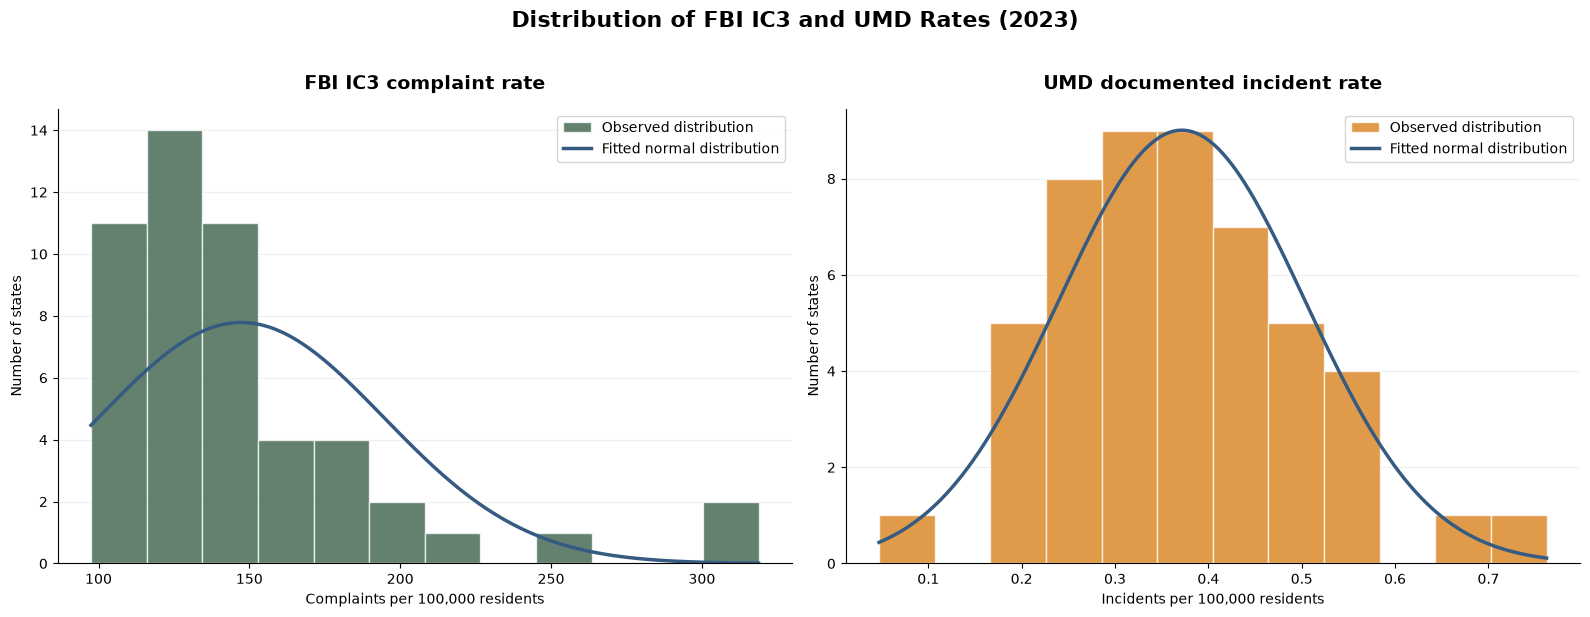

In [46]:
# Distribution assessment: FBI IC3 and UMD rates (2023)
variables = [
    (
        "complaints_per_100k",
        "FBI IC3 complaint rate",
        "Complaints per 100,000 residents",
        "#2F573E"
    ),
    (
        "incidents_per_100k",
        "UMD documented incident rate",
        "Incidents per 100,000 residents",
        "#D67A0D"
    )
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (column, title, xlabel, color) in zip(axes, variables):
    values = comparison_2023[column].dropna().to_numpy()

    counts, edges, _ = ax.hist(
        values,
        bins=12,
        color=color,
        alpha=0.75,
        edgecolor="white",
        label="Observed distribution"
    )

    # Fitted normal distribution
    mu, sigma = norm.fit(values)
    x = np.linspace(values.min(), values.max(), 300)
    bin_width = edges[1] - edges[0]

    expected = norm.pdf(x, mu, sigma) * len(values) * bin_width

    ax.plot(
        x, expected,
        color="#365B83",
        linewidth=2.5,
        label="Fitted normal distribution"
    )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of states")

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()

fig.suptitle(
    "Distribution of FBI IC3 and UMD Rates (2023)",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_12_fbi_umd_rate_distributions_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 3.6.3 Comparison of Economic Associations

GDP per capita and average annual pay are positively associated with both measures after multiple-testing adjustment. Real GDP growth is negatively associated with UMD rates but not with FBI IC3 rates, while unemployment is positively associated with FBI IC3 rates only. The contrasts do not imply causal effects.


In [47]:
# Compute comparable Spearman coefficients in both data sources
rows = []
for source, outcome in {"FBI IC3": "complaints_per_100k", "UMD": "incidents_per_100k"}.items():
    for factor, label in economic_features.items():
        data = comparison_2023[[factor, outcome]].dropna()
        rho, p_value = spearmanr(data[factor], data[outcome])
        rows.append({"Source": source, "Economic factor": label, "N": len(data),
                     "Method": "Spearman", "Coefficient": rho, "p-value": p_value})
economic_comparison = pd.DataFrame(rows)
for source in ("FBI IC3", "UMD"):
    mask = economic_comparison["Source"].eq(source)
    p = economic_comparison.loc[mask,"p-value"].to_numpy(dtype=float)
    order = np.argsort(p)
    adj = np.minimum.accumulate((p[order]*len(p)/np.arange(1,len(p)+1))[::-1])[::-1]
    vals = np.empty_like(adj)
    vals[order] = np.clip(adj,0,1)
    economic_comparison.loc[mask,"BH-adjusted p"] = vals
economic_comparison["BH significant"] = economic_comparison["BH-adjusted p"] < .05
display(economic_comparison.round(4))

,Source,Economic factor,N,Method,Coefficient,p-value,BH-adjusted p,BH significant
0,FBI IC3,GDP per capita,50,Spearman,0.3654,0.0091,0.0205,True
1,FBI IC3,Personal income per capita,50,Spearman,0.3547,0.0115,0.0205,True
2,FBI IC3,Real GDP growth,50,Spearman,0.0049,0.9733,0.9733,False
3,FBI IC3,Unemployment rate,50,Spearman,0.3538,0.0117,0.0205,True
4,FBI IC3,Labor force participation,50,Spearman,0.0820,0.5714,0.8000,False
5,FBI IC3,Establishment density,50,Spearman,-0.0293,0.8397,0.9733,False
6,FBI IC3,Average annual pay,50,Spearman,0.4214,0.0023,0.0161,True
7,UMD,GDP per capita,50,Spearman,0.4841,0.0004,0.0026,True
8,UMD,Personal income per capita,50,Spearman,0.2808,0.0483,0.0676,False
9,UMD,Real GDP growth,50,Spearman,-0.3672,0.0087,0.0214,True


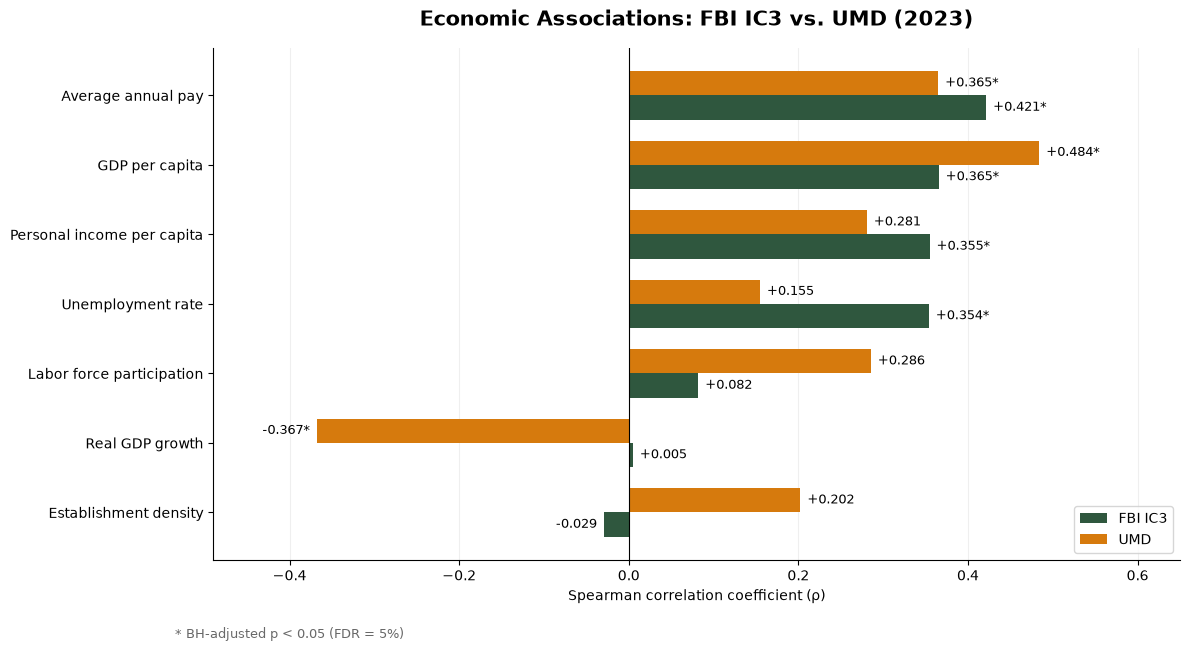

In [48]:
# Compare economic correlations between FBI IC3 and UMD (2023)
factor_order = (
    economic_comparison[economic_comparison["Source"] == "FBI IC3"]
    .sort_values("Coefficient", ascending=True)["Economic factor"]
    .tolist()
)

fbi_results = (
    economic_comparison[economic_comparison["Source"] == "FBI IC3"]
    .set_index("Economic factor")
    .loc[factor_order]
)

umd_results = (
    economic_comparison[economic_comparison["Source"] == "UMD"]
    .set_index("Economic factor")
    .loc[factor_order]
)

y = np.arange(len(factor_order))
height = 0.35

fig, ax = plt.subplots(figsize=(12, 6.5))

bars_fbi = ax.barh(
    y - height / 2,
    fbi_results["Coefficient"],
    height=height,
    color="#2F573E",
    label="FBI IC3"
)

bars_umd = ax.barh(
    y + height / 2,
    umd_results["Coefficient"],
    height=height,
    color="#D67A0D",
    label="UMD"
)

# Coefficient labels and BH significance
for bars, results in [
    (bars_fbi, fbi_results),
    (bars_umd, umd_results)
]:
    for bar, (_, row) in zip(bars, results.iterrows()):
        value = row["Coefficient"]
        marker = "*" if row["BH significant"] else ""

        ax.annotate(
            f"{value:+.3f}{marker}",
            (value, bar.get_y() + bar.get_height() / 2),
            xytext=(5 if value >= 0 else -5, 0),
            textcoords="offset points",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=9
        )

ax.set_yticks(y)
ax.set_yticklabels(factor_order)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.49, 0.65)

ax.set_xlabel("Spearman correlation coefficient (ρ)")
ax.set_title(
    "Economic Associations: FBI IC3 vs. UMD (2023)",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.15, 0.01,
    "* BH-adjusted p < 0.05 (FDR = 5%)",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    STATIC_DIR / "03_13_fbi_umd_economic_correlations_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Key Findings and Limitations

The analysis finds substantial geographic differences in reported complaint volume, loss rates and crime composition. Older complainants account for the largest age-group losses, and ransomware complaints are concentrated in a few critical-infrastructure sectors. Four economic indicators correlate with IC3 complaint rates after correction for multiple testing, but IC3 and UMD state rates are not significantly rank-correlated (ρ = −0.218; p = 0.129).

**Limitations:** IC3 complaints and UMD documented incidents are not equivalent measures. The economic comparisons are observational, limited to 50 states in one year and do not establish causality. The sector table excludes financial losses, age-group data omit unknown ages, and overlapping crime descriptors are not added to primary categories.
